# trackver_mars — ECMWF IFS and AIFS ensemble tropical cyclone forecasts against IBTrACS observations

This notebook does what the `./trackver_mars` command does, step by step, and shows the plots here
instead of saving them:

1. downloads the latest IBTrACS *last3years* best-track file and finds the storm,
2. retrieves the chosen run's BUFR track files from MARS: the IFS ensemble, and the AIFS ensemble for
   runs from 2026-05-12 on,
3. plots, for each model, the wind and pressure meteogram and the track plume map, with the observations on top.

The code lives in the `trackver_mars` program next to this notebook; the notebook loads it as a module.
It needs the `mars` command, so run it on ECMWF's Atos HPC (e.g. through JupyterHub).

In [ ]:
#Uncomment and run pip install if you haven't installed the requirements yet.

#pip install -r requirements.txt

## Settings

* `STORM` — storm name, any case, or IBTrACS storm id (SID). If the name was reused, the storm observed at `RUN` is used.
* `RUN` — base time of the forecast run, `YYYYMMDDHH`: 00, 06, 12 or 18 UTC, while the storm was observed.
  The IFS 00 and 12 UTC runs go up to 360 h ahead; the 06 and 18 UTC runs go up to 144 h.
  AIFS ensemble tracks are in MARS from 2026-05-12; for earlier runs only IFS is plotted.

In [1]:
STORM = "DUJUAN"
RUN = "2026091800"      # YYYYMMDDHH
MAX_HOURS = 240         # last forecast step plotted

In [2]:
from datetime import datetime
from importlib.machinery import SourceFileLoader
from importlib.util import module_from_spec, spec_from_loader

# load the trackver_mars program (a script without the .py ending) as a module
loader = SourceFileLoader("trackver_mars", "trackver_mars")
tv = module_from_spec(spec_from_loader("trackver_mars", loader))
loader.exec_module(tv)

## 1. Observations

The IBTrACS file is downloaded into `obs/`.

In [3]:
base = datetime.strptime(str(RUN), "%Y%m%d%H")

ibtracs = tv.read_ibtracs(tv.download_ibtracs())
track = tv.choose_storm(ibtracs, STORM, at=base)    # the storm observed at the run's base time
obs, obs_label = tv.observed_intensity(track)

name, sid = track.NAME.iloc[0], "+".join(track.SID.unique())
print(f"{name} ({sid}), {len(track)} positions, intensity from {obs_label}")
obs.head()

IBTrACS: https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.last3years.list.v04r01.csv
DUJUAN (2026259N15149), 57 positions, intensity from IBTrACS: tcvitals 1-min


,wind,mslp,LAT,LON
time,,,,
2026-09-15 12:00:00,25.0,1003.0,14.9,148.9
2026-09-15 15:00:00,27.0,1002.0,14.8,148.9
2026-09-15 18:00:00,29.0,1000.0,14.8,148.8
2026-09-15 21:00:00,29.0,1000.0,14.9,148.7
2026-09-16 00:00:00,29.0,999.0,15.0,148.7


## 2. Retrieve the forecasts from MARS

The files are kept in `forecasts/`, so running this cell again does not go back to MARS. The storm is
found by name when the analysed centre is close to the observed one, otherwise as the analysed storm
nearest the observed position (e.g. before it was named).

In [4]:
bases = tv.candidate_runs(track, obs)      # runs that started while the storm was observed
if base not in bases:
    raise tv.TrackverError(f"no run at {base:%Y-%m-%d %H} UTC for {name}; runs are "
                           f"from {bases[0]:%Y%m%d%H} to {bases[-1]:%Y%m%d%H}, every 6 hours")

storms = tv.forecast_storms(base, track)   # {"ifs": ..., "aifs": ...}, AIFS from 2026-05-12
figures = {model: tv.make_plots(storm, track, base, obs, obs_label, MAX_HOURS, model)
           for model, storm in storms.items()}
tv.share_limits(list(figures.values()))    # same axes for IFS and AIFS
tv.plt.close("all")     # shown one by one below

IFS: using ifs_enfo_tf_2026091800.bufr, retrieved earlier
AIFS: using aifs_enfo_tf_2026091800.bufr, retrieved earlier
Found DUJUAN in the IFS forecast by name.
Found DUJUAN in the AIFS forecast by name.


## 3. Meteograms

The boxes span the ensemble (50 perturbed members plus the control): whiskers from the minimum to the
maximum, the box over the interquartile range, the median inside. The black lines are the control
(dotted) and the member the file marks as the high-resolution or deterministic forecast (solid), the
dashed line the ensemble mean, and the red stars the observations at the forecast steps. IFS and AIFS
are drawn on the same axes.

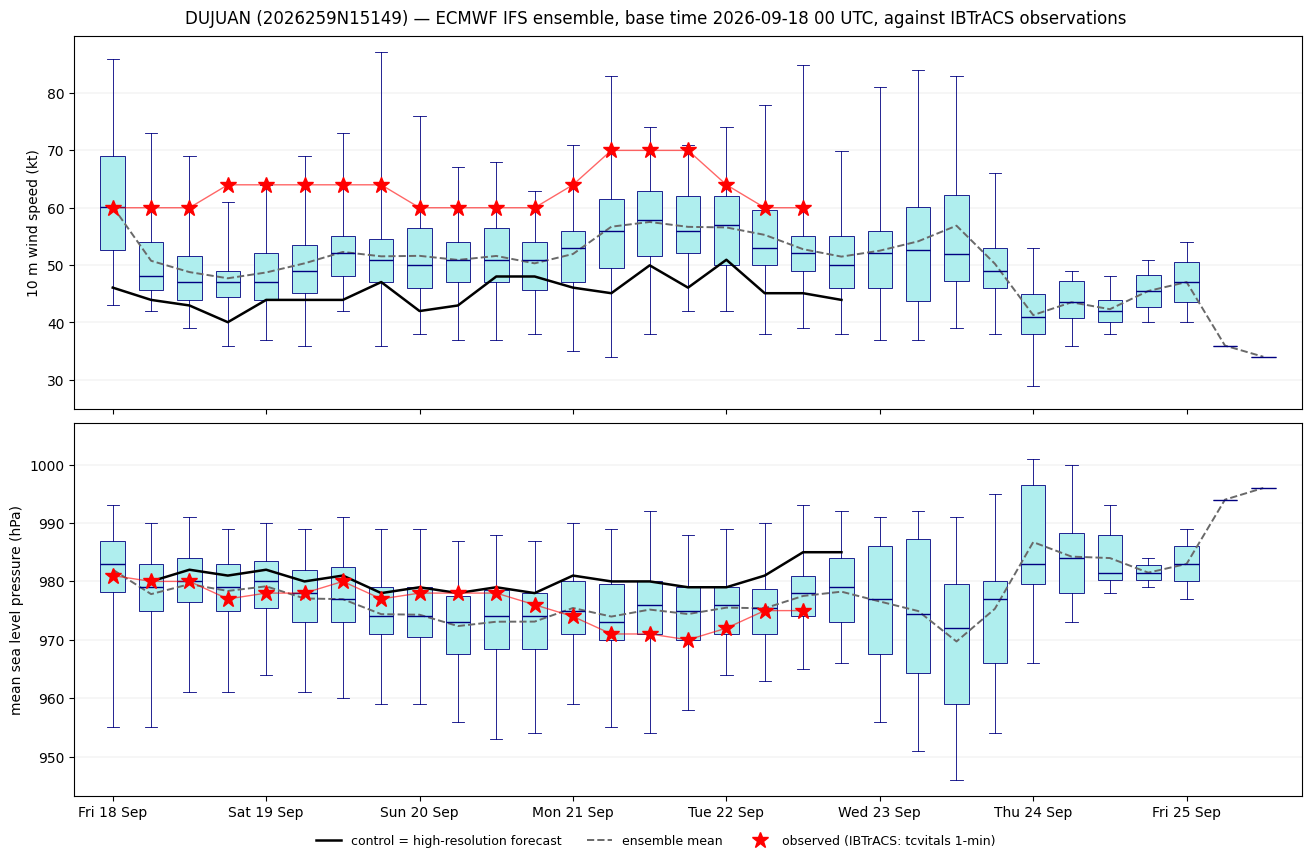

In [5]:
figures["ifs"][0]

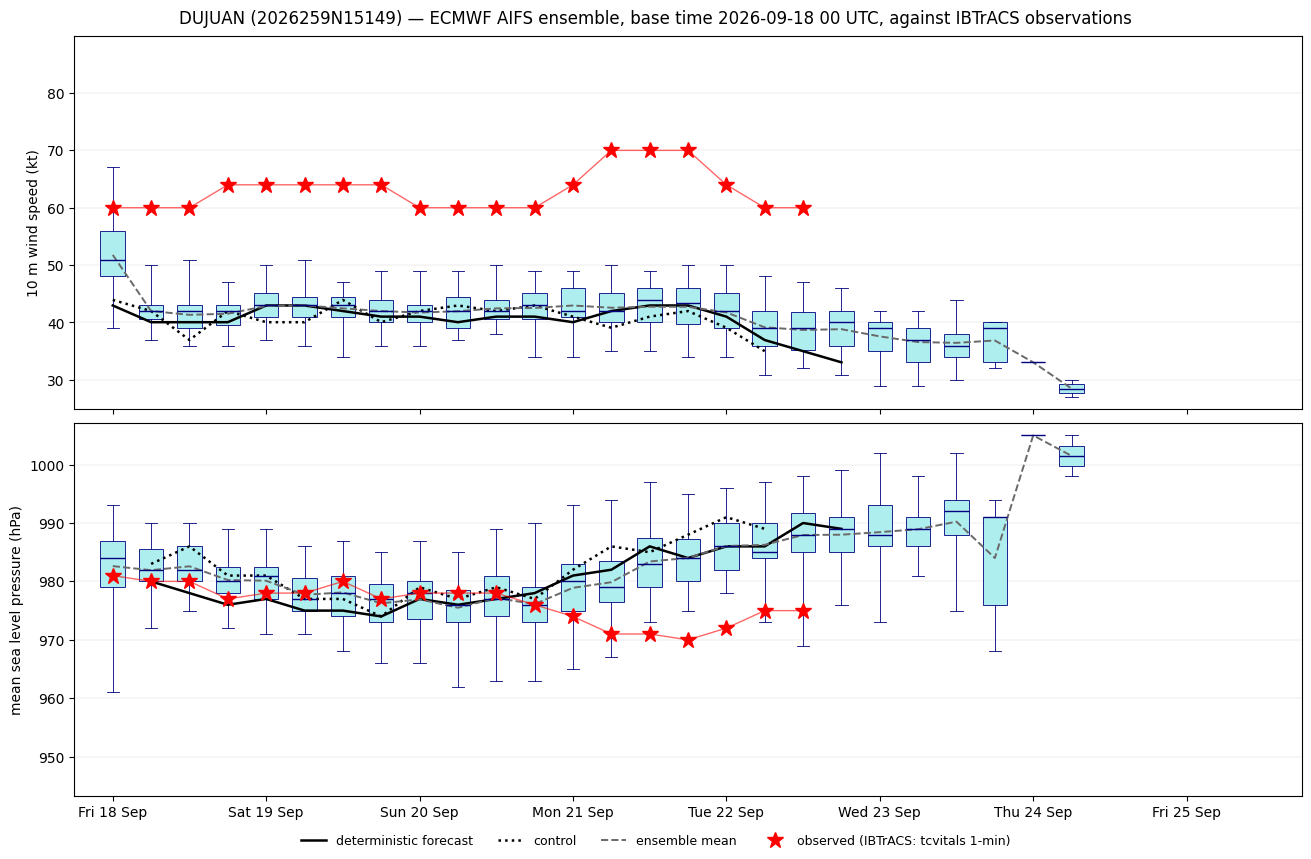

In [6]:
figures["aifs"][0] if "aifs" in figures else print("no AIFS forecast for this run")

## 4. Plume maps

Every member's track, coloured by lead time in 24-hour bands, with the control and the high-resolution
or deterministic forecast in black. The red dots are the observed positions at the forecast steps,
every 6 hours.

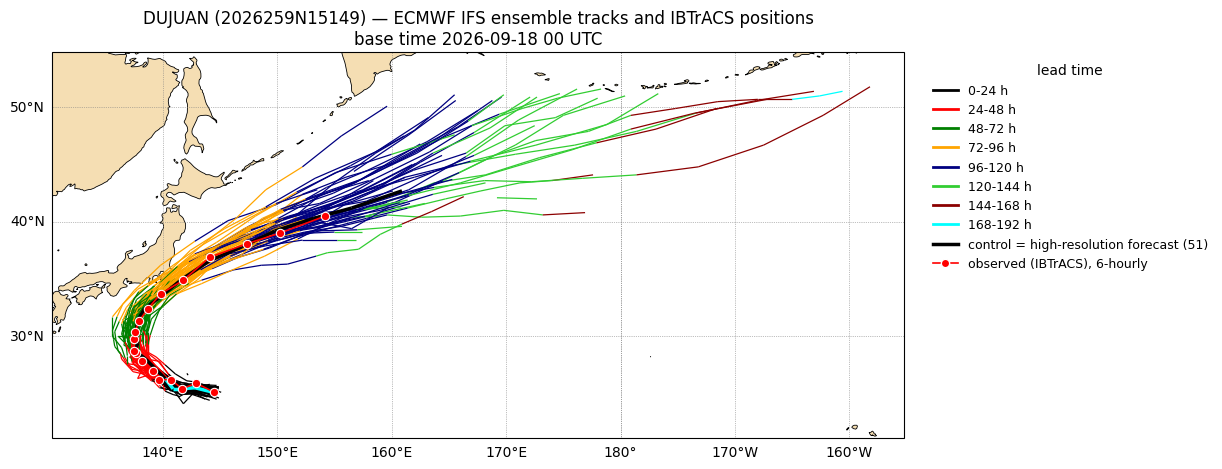

In [7]:
figures["ifs"][1]

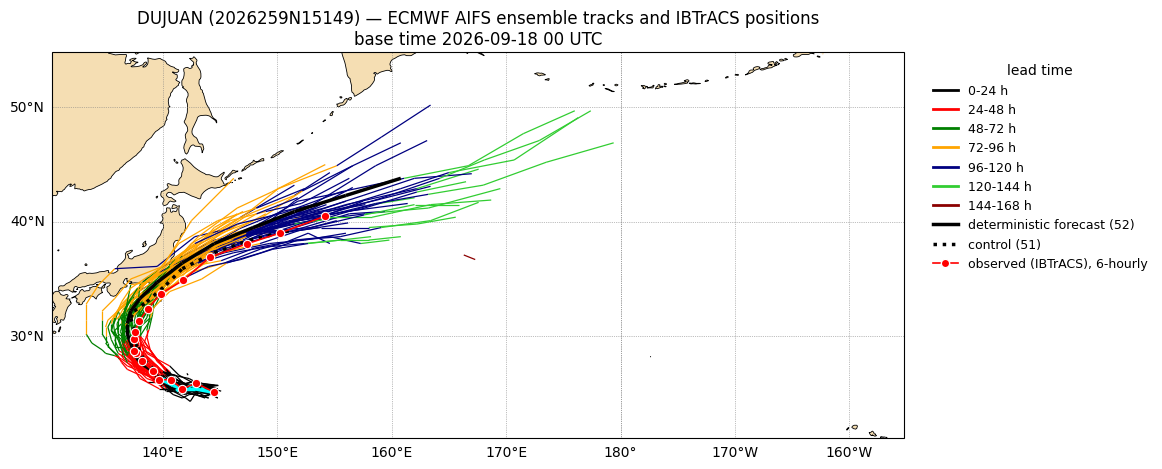

In [8]:
figures["aifs"][1] if "aifs" in figures else print("no AIFS forecast for this run")